 BÁO CÁO THỰC HÀNH: XÂY DỰNG MÔ HÌNH HỒI QUY TUYẾN TÍNH

 Bộ dữ liệu sử dụng: Diabetes Dataset (từ thư viện scikit-learn)

---

# 1. MỤC TIÊU VÀ BỐI CẢNH BÀI TOÁN

 1.1. Bối cảnh thực tế
Tiểu đường là một bệnh mãn tính phổ biến với tốc độ gia tăng nhanh. Việc dự đoán chính xác mức độ tiến triển của bệnh giúp bác sĩ đưa ra phác đồ điều trị kịp thời và hạn chế biến chứng cho bệnh nhân.

 1.2. Định nghĩa bài toán Machine Learning
- Loại bài toán: Hồi quy (Regression) – Học có giám sát.
- Mục tiêu: Sử dụng thuật toán Hồi quy tuyến tính để dự đoán mức độ tiến triển của bệnh tiểu đường sau 1 năm.
- Đầu vào (10 đặc trưng định lượng đã chuẩn hóa):
  1. "age": Tuổi
  2. "sex": Giới tính
  3. "bmi": Chỉ số khối cơ thể
  4. "bp": Huyết áp trung bình
  5. "s1": Tổng lượng Cholesterol (T-Cells)
  6. "s2": Cholesterol xấu (LDL)
  7. "s3": Cholesterol tốt (HDL)
  8. "s4": Nồng độ hormone giáp (TSH)
  9. "s5": Logarit nồng độ Triglycerides
  10. "s6": Nồng độ đường trong máu
- Đầu ra (Biến mục tiêu target): Chỉ số tiến triển của bệnh sau 1 năm (giá trị liên tục từ 25 đến 346).

 1.3. Các bước thực hiện chính
1. Khám phá dữ liệu (EDA): Phân tích phân phối, tìm mối tương quan giữa các biến và phát hiện dữ liệu ngoại lệ.
2. Lựa chọn đặc trưng: Xác định các yếu tố ảnh hưởng chính (như bmi, s5, bp) và kiểm tra hiện tượng đa cộng tuyến.
3. Huấn luyện mô hình:
   - Xây dựng mô hình Hồi quy tuyến tính đơn biến và đa biến.
   - Trải nghiệm thêm các mô hình Ràng buộc (Ridge và Lasso) để tối ưu kết quả.
4. Đánh giá mô hình:
   - Đo lường độ chính xác qua các chỉ số MAE, MSE, RMSE và R2 Score.
   - Phân tích phần dư (Residuals) để kiểm tra độ tin cậy của mô hình.

In [5]:
#Cell 1

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes

# 1. Tải bộ dữ liệu Diabetes
diabetes = load_diabetes(as_frame=True)
df = diabetes.data.copy()
df["target"] = diabetes.target.copy()

# 2. Chọn 3 feature để phân tích
selected_features = ["bmi", "bp", "s5"]
print("3 feature được chọn:", selected_features)
display(df[selected_features + ["target"]].head())

3 feature được chọn: ['bmi', 'bp', 's5']


,bmi,bp,s5,target
0,0.061696,0.021872,0.019907,151.0
1,-0.051474,-0.026328,-0.068332,75.0
2,0.044451,-0.005670,0.002861,141.0
3,-0.011595,-0.036656,0.022688,206.0
4,-0.036385,0.021872,-0.031988,135.0


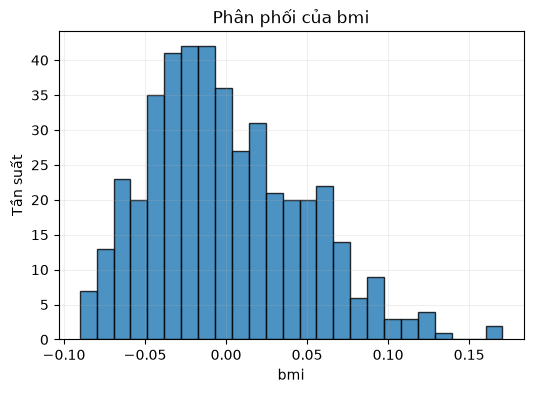

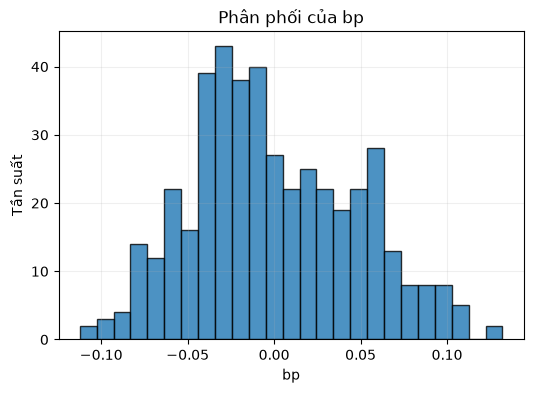

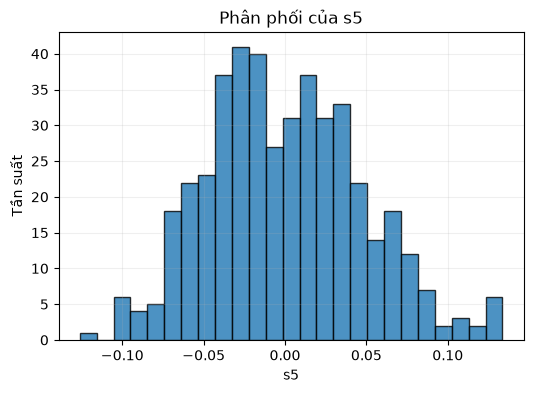

,count,mean,std,min,25%,50%,75%,max
bmi,442.0,-2.245564e-16,0.047619,-0.090275,-0.034229,-0.007284,0.031248,0.170555
bp,442.0,-4.797570e-17,0.047619,-0.112399,-0.036656,-0.005670,0.035644,0.132044
s5,442.0,9.268604e-17,0.047619,-0.126097,-0.033246,-0.001947,0.032432,0.133597


In [6]:
#Cell 2

# Phân tích phân phối của 3 feature
for col in selected_features:
    plt.figure(figsize=(6, 4))
    plt.hist(df[col], bins=25, edgecolor="black", alpha=0.8)
    plt.title(f"Phân phối của {col}")
    plt.xlabel(col)
    plt.ylabel("Tần suất")
    plt.grid(alpha=0.2)
    plt.show()

# Thống kê mô tả
display(df[selected_features].describe().T)

In [7]:
#Cell 3

# Phát hiện Outlier theo phương pháp IQR
outlier_summary = []
for col in selected_features:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    
    n_outliers = ((df[col] < lower) | (df[col] > upper)).sum()
    outlier_summary.append([col, n_outliers, lower, upper])

outlier_df = pd.DataFrame(
    outlier_summary, 
    columns=["Biến", "Số ngoại lệ (IQR)", "Ngưỡng dưới", "Ngưỡng trên"]
)
display(outlier_df)

,Biến,Số ngoại lệ (IQR),Ngưỡng dưới,Ngưỡng trên
0,bmi,3,-0.132445,0.129464
1,bp,0,-0.145106,0.144094
2,s5,4,-0.131762,0.130949


Hệ số tương quan với target:


,corr_with_target
bmi,0.586450
s5,0.565883
bp,0.441482


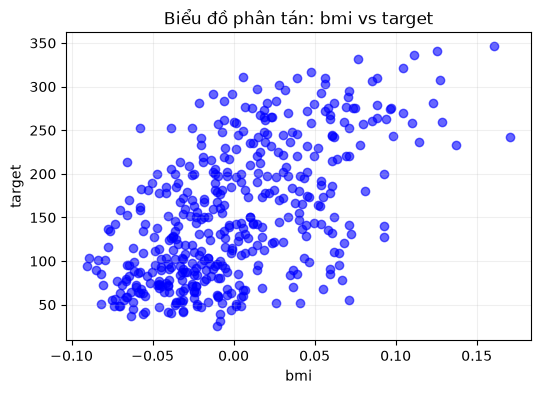

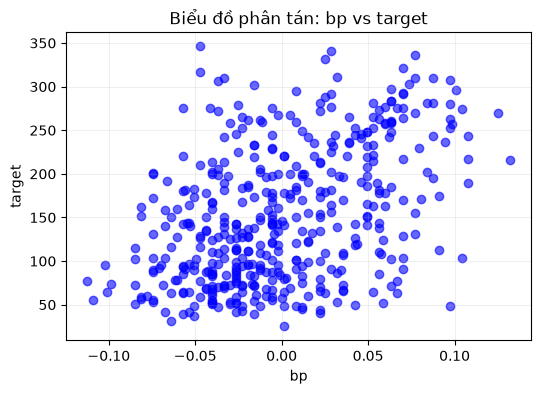

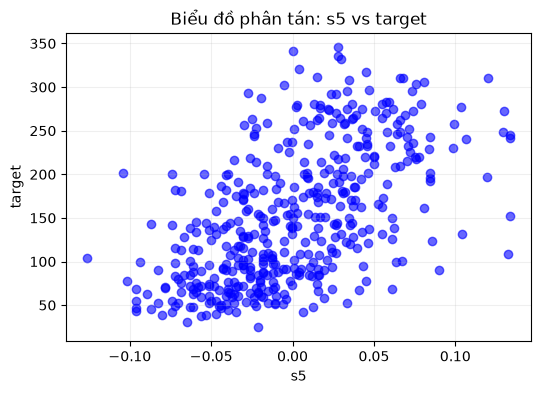

In [8]:
#Cell 4

# 1. Ma trận tương quan với biến target
corr = df[selected_features + ["target"]].corr()
target_corr = corr["target"].drop("target").sort_values(ascending=False)
print("Hệ số tương quan với target:")
display(target_corr.to_frame("corr_with_target"))

# 2. Biểu đồ phân tán (Scatter Plot) với target
for col in selected_features:
    plt.figure(figsize=(6, 4))
    plt.scatter(df[col], df["target"], alpha=0.6, color="blue")
    plt.xlabel(col)
    plt.ylabel("target")
    plt.title(f"Biểu đồ phân tán: {col} vs target")
    plt.grid(alpha=0.2)
    plt.show()